### TEL328 - Procesamiento Digital de Imágenes
# Clase 8: Clasificación de imágenes
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Clasificación de imágenes

<div align="center">
    <img src="img/Classification.png" alt="" width="70%" align="center" />
</div>

# En Python... 

Keras es una librería de alto nivel para trabajar con modelos de aprendizaje automático (ML), con enfoque en el aprendizaje profundo moderno. En tanto, la librería TensorFlow realiza las operaciones matemáticas a bajo nivel y sirve como el motor backend de Keras.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Para ocultar los warnings de tensorflow
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

In [3]:
import tensorflow as tf
from tensorflow import keras
tf.keras.backend.clear_session()

# Fashion MNIST

El conjunto de datos Fashion MNIST es una gran base de datos disponible gratuitamente de imágenes de moda que se usa comúnmente para entrenar y probar varios sistemas de aprendizaje automático

In [4]:
fashion_mnist = keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

## Conjunto de entrenamiento

Contiene 60.000 imágenes etiquetadas en escala de grises, cada una de 28x28 píxeles.

In [5]:
X_train_full.shape

(60000, 28, 28)

In [6]:
# Etiquetas:
y_train_full

array([9, 0, 0, ..., 3, 0, 5], dtype=uint8)

In [7]:
y_train_full.shape

(60000,)

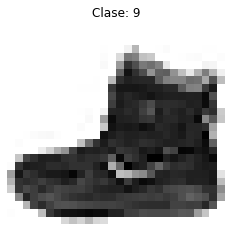

In [8]:
plt.imshow(X_train_full[0], cmap="binary")
plt.title(f"Clase: {y_train_full[0]}")
plt.axis('off')
plt.show()

## Clases

Cada ejemplo es una imagen en escala de grises de 28x28 píxeles, asociada con una etiqueta entre alguna de 10 clases.

In [9]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", 
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

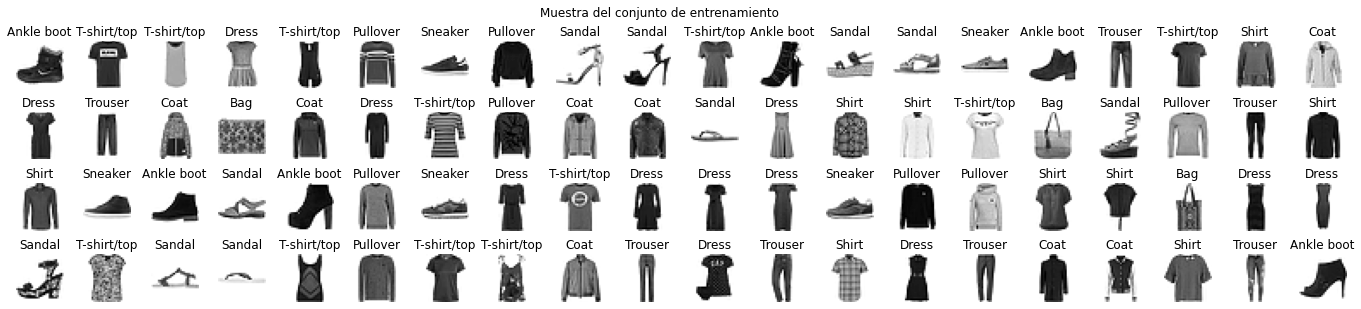

In [10]:
n_rows = 4
n_cols = 20
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
plt.suptitle("Muestra del conjunto de entrenamiento")
for row in range(n_rows):
    for col in range(n_cols):
        index = n_cols * row + col
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(X_train_full[index], cmap="binary")
        plt.axis('off')
        plt.title(class_names[y_train_full[index]])
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

## Conjunto de validación y normalización

Se utiliza una pequeña parte del conjunto de entrenamiento para validación (ajustar parámetros). Además, se escalan las intensidades de los píxeles hasta el rango 0-1 dividiéndolos por 255.0 (esto también los convierte en flotantes).

In [11]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.

In [12]:
X_valid.shape

(5000, 28, 28)

El conjunto de validación contiene 5000 imágenes.

## Configuración de la red neuronal

### Modelo secuencial

Comenzamos por instanciar un objeto creado con `Sequential`. Con este vamos a poder concatenar múltiples capas.

In [13]:
model = keras.models.Sequential()

### Añadir capas al modelo

Posteriomente, debemos agregar una capa con el método `add` sobre nuestro objeto instanciado. En esta parte definimos las características de las capas: Cantidad de Neuronas, Dimensiones del Input (ésta sólo es necesaria para la primera capa) y función de activación.

In [14]:
# Capa de entrada
model.add(keras.layers.Flatten(input_shape=[28, 28]))

#### Capa Flatten

La primera capa de la red debe ser de tipo `Flatten`, la cual transforma las imagenes de un arreglo bidimensional (28 x 28 pixeles) a un arreglo unidimensional de 784 x 1 . Piense en esta capa como una columna de pixeles alineados de la imagen. Esta capa no tiene parámetros que aprender; solo reformatea la entrada.

<div align="center">
    <img src="img/flattening.jpg" alt="" width="40%" align="center" />
</div>

#### Capas ocultas

In [15]:
model.add(keras.layers.Dense(300, activation="relu"))
model.add(keras.layers.Dense(100, activation="relu"))

#### Capa de salida

In [16]:
model.add(keras.layers.Dense(10, activation="softmax"))

In [17]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 300)               235500    
                                                                 
 dense_1 (Dense)             (None, 100)               30100     
                                                                 
 dense_2 (Dense)             (None, 10)                1010      
                                                                 
Total params: 266,610
Trainable params: 266,610
Non-trainable params: 0
_________________________________________________________________


## Compilación del modelo

Antes de que el modelo esté listo para su entrenamiento, se necesita compilar indicando:

- `loss` — Función de pérdida que el modelo va a minimizar.
- `optimizer` — Optimizador (algoritmo que utiliza el modelo para minimizar la funcion de pérdida).
- `metrics` — Métrica para evaluar la calidad del modelo. En clasificación se suele utilizar `accuracy`, que mide la fraccion de imágenes que son correctamente clasificadas.

In [18]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

## Entrenamiento del modelo

Se puede usar la API [ModelCheckpoint](https://keras.io/api/callbacks/#modelcheckpoint) para ir guardando los pesos del modelo durante el entranamiento (útil en caso de interrupción). El parámetro `save_best_only = True` permite guardar solo cuando mejora la accuracy sobre los datos de validación.

In [19]:
checkpointer = tf.keras.callbacks.ModelCheckpoint(filepath='weights/fashion_mnist/cp.ckpt',
                               save_weights_only = True,
                               verbose = 1, save_best_only=True)

## Cargar pesos (solo si ya fue entrenado)

Si el entrenamiento ya se realizó anteriormente, y se guardaron los pesos, simplemente se puede cargar y realizar predicciones.

In [20]:
model.load_weights("weights/fashion_mnist/cp.ckpt")

## Entrenar (Ajustar parámetros)

El entrenamiento es la etapa de ajuste de parámetros, que son los pesos de la red, a través del método `fit`, indicando la cantidad de iteraciones o épocas (`epochs`).

In [22]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid), 
                    callbacks=[checkpointer])

Epoch 1/30
1714/1719 [============================>.] - ETA: 0s - loss: 0.2248 - accuracy: 0.9187
Epoch 1: val_loss improved from inf to 0.32613, saving model to weights/fashion_mnist/cp.ckpt
1719/1719 [==============================] - 4s 2ms/step - loss: 0.2249 - accuracy: 0.9187 - val_loss: 0.3261 - val_accuracy: 0.8760
Epoch 2/30
1708/1719 [============================>.] - ETA: 0s - loss: 0.2214 - accuracy: 0.9197
Epoch 2: val_loss improved from 0.32613 to 0.32362, saving model to weights/fashion_mnist/cp.ckpt
1719/1719 [==============================] - 3s 2ms/step - loss: 0.2215 - accuracy: 0.9197 - val_loss: 0.3236 - val_accuracy: 0.8888
Epoch 3/30
1708/1719 [============================>.] - ETA: 0s - loss: 0.2181 - accuracy: 0.9222
Epoch 3: val_loss improved from 0.32362 to 0.30486, saving model to weights/fashion_mnist/cp.ckpt
1719/1719 [==============================] - 3s 2ms/step - loss: 0.2184 - accuracy: 0.9220 - val_loss: 0.3049 - val_accuracy: 0.8912
Epoch 4/30
1719/1

1697/1719 [============================>.] - ETA: 0s - loss: 0.1434 - accuracy: 0.9493
Epoch 29: val_loss did not improve from 0.28875
1719/1719 [==============================] - 3s 2ms/step - loss: 0.1433 - accuracy: 0.9494 - val_loss: 0.3073 - val_accuracy: 0.8972
Epoch 30/30
1706/1719 [============================>.] - ETA: 0s - loss: 0.1407 - accuracy: 0.9509
Epoch 30: val_loss did not improve from 0.28875
1719/1719 [==============================] - 3s 2ms/step - loss: 0.1407 - accuracy: 0.9509 - val_loss: 0.3193 - val_accuracy: 0.8944


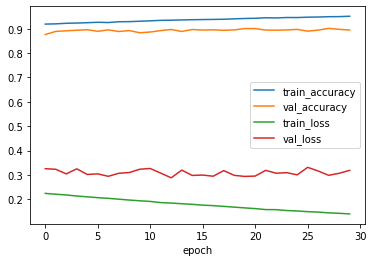

In [23]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.legend(['train_accuracy', 'val_accuracy','train_loss', 'val_loss'], loc='best')
plt.show()

## Predicción del modelo

Después de entrenar el modelo puede predecir sobre datos nuevos del conjunto de testing.

In [24]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=-1)

313/313 [==============================] - 0s 1ms/step


In [25]:
y_prob[0]

array([3.1317505e-08, 1.6040165e-07, 1.1765974e-07, 8.1710496e-08,
       3.7045247e-08, 6.8465364e-04, 2.1660831e-08, 6.7489420e-04,
       1.0288739e-05, 9.9862975e-01], dtype=float32)

In [26]:
y_pred[0]

9

## Conjunto de testing

Imágenes que se utilizan para que el modelo realice predicciones sin decirle las etiquetas reales. Luego, se comparan la predicciones del modelo con respecto a las etiquetas reales para calcular la accuracy.

In [27]:
X_test.shape

(10000, 28, 28)

El conjunto de prueba contiene 10.000 imágenes.

In [31]:
def plot_image(i):
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_test[i], cmap=plt.cm.binary)
    color = ("blue" if y_pred[i] == y_test[i] else "red")
    plt.xlabel("{} {:2.0f}% ({})".format(np.array(class_names)[y_pred[i]],
                                100*np.max(y_prob[i]),
                                class_names[y_test[i]]),
                                color=color)

In [40]:
def plot_histo(i):
    plt.xticks(
        range(len(class_names)),
        class_names,
        rotation=90
    )
    plt.yticks(np.arange(0, 1.1, 0.2))
    
    thisplot = plt.bar(
        range(len(class_names)),
        y_prob[i],
        color="#777777"
    )
    plt.ylim([0, 1])
    
    predicted_label = np.argmax(y_prob[i])
    thisplot[predicted_label].set_color('red')
    thisplot[y_test[i]].set_color('blue')

In [33]:
def plot_results(i, j=None):
    if j is None:
        j = i

    n = j - i + 1

    plt.figure(figsize=(3 * n, 5))

    for k, idx in enumerate(range(i, j + 1)):
        # Imagen arriba
        plt.subplot(2, n, k + 1)
        plot_image(idx)

        # Histograma abajo
        plt.subplot(2, n, n + k + 1)
        plot_histo(idx)

    plt.tight_layout()
    plt.show()

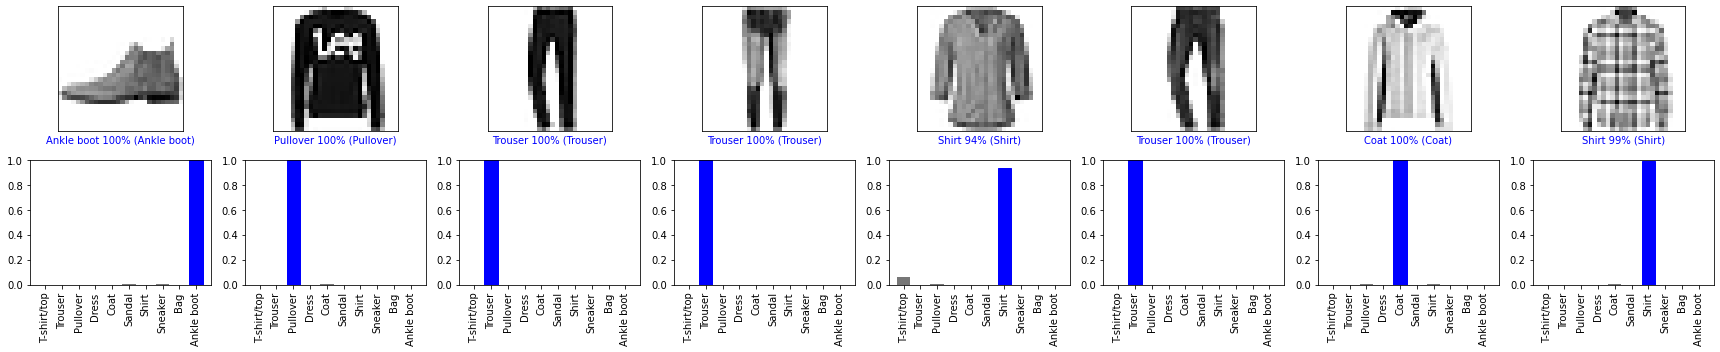

In [44]:
plot_results(0,7)

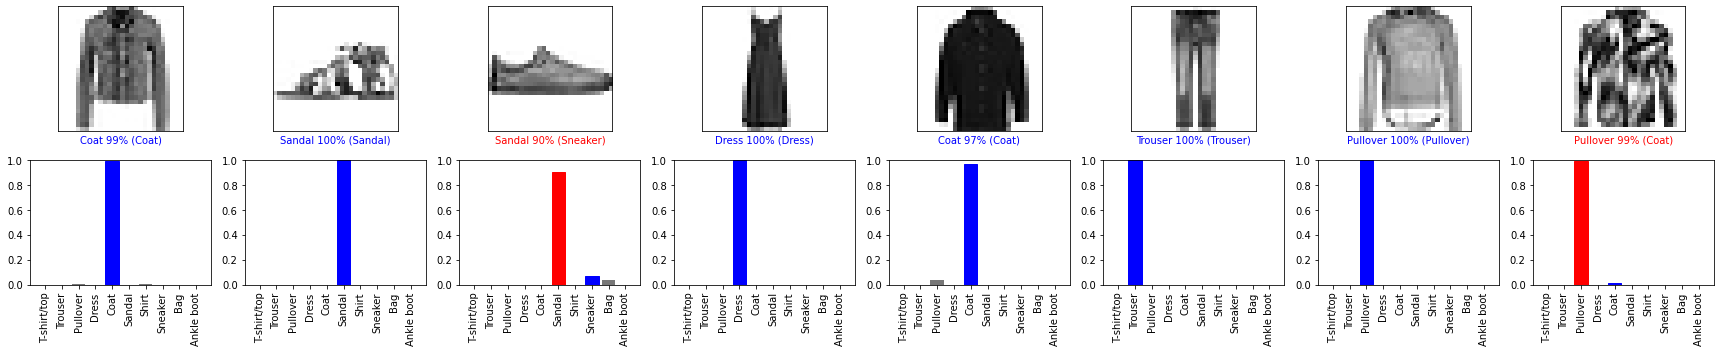

In [47]:
plot_results(10,17)

In [60]:
def plot_predictions(n_rows, n_cols):
    n_images = n_rows * n_cols

    # Contar aciertos y fallos
    correct = np.sum(y_pred[:n_images] == y_test[:n_images])
    incorrect = n_images - correct
    accuracy = correct / n_images * 100

    plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))

    plt.suptitle(
        f"Algunas predicciones sobre el conjunto de testing\n"
        f"Accuracy: {accuracy:.2f}% — "
        f"{correct} aciertos / {incorrect} fallos",
        fontsize=16
    )

    for row in range(n_rows):
        for col in range(n_cols):
            index = n_cols * row + col

            plt.subplot(n_rows, n_cols, index + 1)

            plt.imshow(X_test[index], cmap="binary")
            plt.xticks([])
            plt.yticks([])

            plt.title(
                class_names[y_pred[index]],
                color=("blue" if y_pred[index] == y_test[index] else "red"),
                fontsize=9
            )

            plt.xlabel(
                class_names[y_test[index]],
                fontsize=8
            )

    # Más espacio arriba para separar el título de los subplots
    plt.subplots_adjust(
        wspace=0.2,
        hspace=1,
        top=0.8
    )

    plt.show()

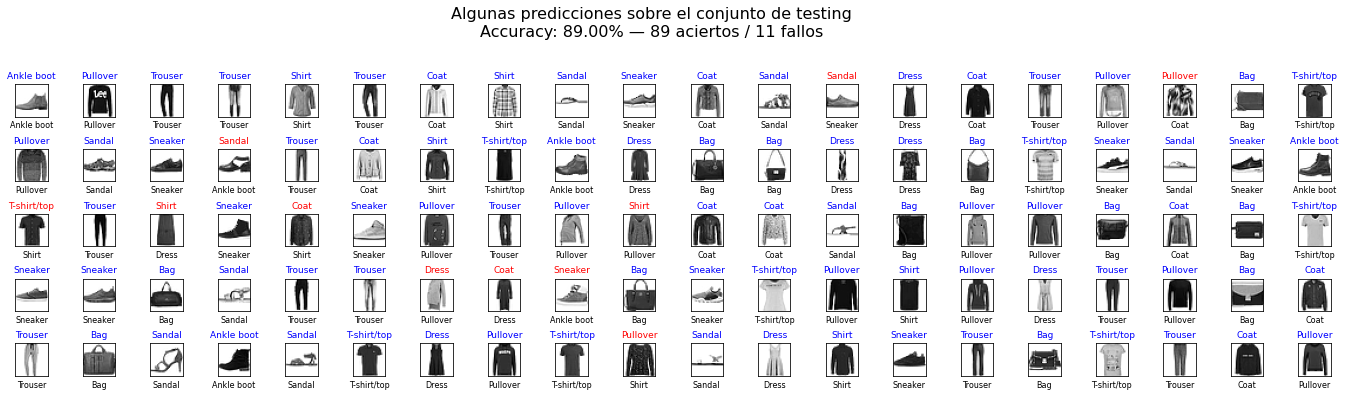

In [62]:
plot_predictions(n_rows=5, n_cols=20)

## Evaluación

Finalmente, se evalúa la calidad del modelo al predecir datos nuevos.

In [30]:
model.evaluate(X_test, y_test)

313/313 [==============================] - 1s 1ms/step - loss: 0.3365 - accuracy: 0.8813


[0.3354949653148651, 0.8813999891281128]

# Redes Neuronales Pre-Entrenadas

## ResNet50
ResNet50 fue entrenado con millones de imágenes de Imagenet. Este dataset contiene 1000 clases diferentes.

In [63]:
resnet50_model = keras.applications.resnet50.ResNet50(weights="imagenet")

In [64]:
import ast, pandas as pd
with open('imagenet1000_labels.txt') as f:
    data = f.read()
d = ast.literal_eval(data)
pd.DataFrame(pd.Series(d,index=d.keys()),columns=["Clase"])

,Clase
0,"tench, Tinca tinca"
1,"goldfish, Carassius auratus"
2,"great white shark, white shark, man-eater, man..."
3,"tiger shark, Galeocerdo cuvieri"
4,"hammerhead, hammerhead shark"
...,...
995,earthstar
996,"hen-of-the-woods, hen of the woods, Polyporus ..."
997,bolete
998,"ear, spike, capitulum"


In [65]:
def clasificar(model, filename, classes=None, height=224, width=224, K=5):
    image = plt.imread(filename)
    image_resize = tf.image.resize(np.array([image]), [height, width])
    inputs = keras.applications.resnet50.preprocess_input(image_resize)    
    Y_proba = model.predict(inputs)
    if classes:
        top_K = sorted(list(zip(range(len(classes)), classes, Y_proba[0])), key = lambda x: x[2], reverse=True)[:K] 
    else:
        top_K = keras.applications.resnet50.decode_predictions(Y_proba, top=K)[0]    
    plt.figure(figsize = (15,2))
    plt.axis('off')
    plt.imshow(image)
    plt.title(f"{top_K[0][1]} ({round(top_K[0][2] * 100,2)}%)")
    plt.show()    
    for _, name, y_proba in top_K:
        print("{:.2f}%\t{:12s}".format(y_proba * 100, name))

1/1 [==============================] - 1s 888ms/step


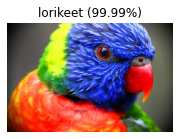

99.99%	lorikeet    
0.01%	macaw       
0.00%	hummingbird 
0.00%	indigo_bunting
0.00%	bee_eater   


In [66]:
clasificar(resnet50_model, "test/lorito.jpg")

In [67]:
def clasificar_todo(model, imgs, classes=None, height=224, width=224):
    list_of_images, list_of_names = imgs
    n_rows = len(list_of_images)-1//5+1
    images = np.array(list_of_images, dtype=np.uint8)
    plt.figure(figsize = (15,n_rows*3))
    images_resized = tf.image.resize(images, [height, width])
    inputs = keras.applications.resnet50.preprocess_input(images_resized)
    Y_proba = model.predict(inputs)
    if classes:
        top_K = []
        for image_index in range(len(images)):
            id_class, name_class, prob_class = sorted(
                list(zip(range(len(classes)), classes, Y_proba[image_index])), 
                key = lambda x: x[2], reverse=True)[0] 
            top_K.append([(id_class, name_class, prob_class)])
    else:
        top_K = keras.applications.resnet50.decode_predictions(Y_proba, top=1)
    for image_index in range(len(images)):
        plt.subplot(n_rows, 5, image_index + 1)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(images[image_index])
        _, name, y_proba = top_K[image_index][0]
        plt.title(f"{name[:12]} ({round(y_proba * 100,2)}%)")
        plt.xlabel(list_of_names[image_index])
    plt.subplots_adjust(wspace=0.2, hspace=0.5)

In [68]:
import re

In [69]:
def imagenes(directory, height=224, width=224):
    list_of_images = []
    list_of_names = []
    for filename in os.listdir(directory):
        f = os.path.join(directory, filename)
        if re.search("\.(jpg)$", filename):
            img = keras.preprocessing.image.load_img(f, target_size=(height, width))
            x = keras.preprocessing.image.img_to_array(img)
            list_of_images.append(x)
            list_of_names.append(filename)
    return list_of_images,list_of_names

1/1 [==============================] - 1s 722ms/step


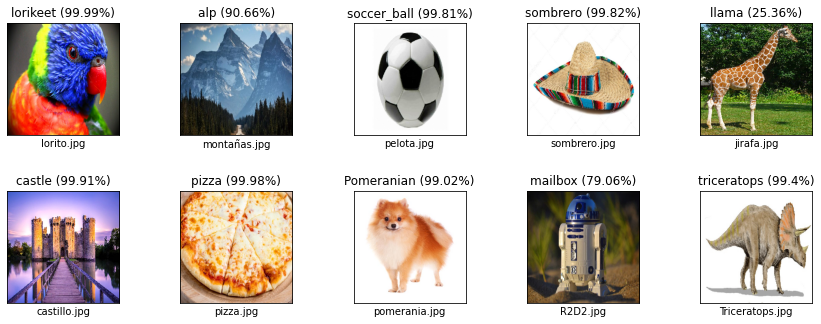

In [70]:
clasificar_todo(resnet50_model, imagenes('test'))

# Predecir flores

1/1 [==============================] - 0s 356ms/step


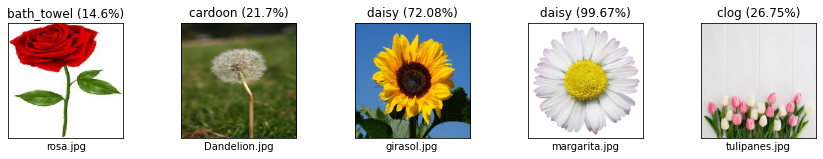

In [71]:
clasificar_todo(resnet50_model, imagenes('flores'))

# Transfer Learning

- Permite transferir conocimientos aprendidos de un problema a otro.
- Metodología de Deep Learning en la que un modelo que se ha entrenado para una tarea se utiliza como punto de partida para un modelo que realiza otra tarea similar.

<div align="center">
    <img src="img/TransferLearning.png" alt="" width="40%" align="center" />
</div>

## Dataset tf_flowers

Se trabajará con un gran conjunto de imágenes de flores. Sin embargo, puede utilizar este enfoque para cualquier otro contexto. El conjunto de datos contiene 5 clases de flores, para las cuales intentaremos mejorar la clasificación del modelo ResNet50.

In [72]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)

In [73]:
img_height,img_width=180,180
batch_size=32
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [74]:
flowers = train_ds.class_names
print(flowers)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [75]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


## Importar un modelo preentrenado y personalizarlo

Por ahora, vamos a usar ResNet-50 y adaptarlo a nuestros datos, pero el mismo procedimiento también se puede usar para cualquier otro modelo.

Al importar la clase ResNet50, el parámetro `include_top=False` garantiza que podamos agregar nuestras propias capas de entrada y salida personalizadas de acuerdo con nuestros datos. 

Además, `layer.trainable= False`, para todas las capas, asegura que el modelo no vuelva a aprender los pesos, ahorrándonos mucho tiempo y complejidad espacial.

In [76]:
custom_resnet_model = keras.models.Sequential()

pretrained_model= tf.keras.applications.ResNet50(include_top=False,
                   input_shape=(180,180,3),
                   pooling='avg',classes=5,
                   weights='imagenet')

for layer in pretrained_model.layers:
        layer.trainable=False

custom_resnet_model.add(pretrained_model)

## Configurar el modelo personalizado

Se agrega una capa de entrada, una oculta con activación `relu` y en la capa de salida usamos activación `softmax` con 5 neuronas de salida correspondientes a las 5 clases de flores en nuestros datos.

In [77]:
custom_resnet_model.add(keras.layers.Flatten())
custom_resnet_model.add(keras.layers.Dense(512, activation='relu'))
custom_resnet_model.add(keras.layers.Dense(5, activation='softmax'))

In [78]:
custom_resnet_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 2048)              23587712  
                                                                 
 flatten_1 (Flatten)         (None, 2048)              0         
                                                                 
 dense_3 (Dense)             (None, 512)               1049088   
                                                                 
 dense_4 (Dense)             (None, 5)                 2565      
                                                                 
Total params: 24,639,365
Trainable params: 1,051,653
Non-trainable params: 23,587,712
_________________________________________________________________


El punto clave a tener en cuenta aquí es que la cantidad total de parámetros en el modelo Resnet50 es de 24 millones. Sin embargo, los parámetros entrenables son solo 1 millón. Así es precisamente como el aprendizaje por transferencia nos ahorra mucho tiempo, espacio y complejidad computacional.

## Compilar el modelo personalizado

In [79]:
custom_resnet_model.compile(optimizer="sgd",loss='sparse_categorical_crossentropy',metrics=['accuracy'])

## Entrenar el modelo personalizado

Se entrena el modelo personalizado y se guardan los pesos para poder cargarlos en otro momento sin necesidad de pasar nuevamente por la fase de entrenamiento.

In [ ]:
checkpointer = tf.keras.callbacks.ModelCheckpoint(filepath='weights/tf_flowers/cp.ckpt',
                               save_weights_only = True,
                               verbose = 1, save_best_only=True)

In [22]:
history = custom_resnet_model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[checkpointer])

Epoch 1/10
92/92 [==============================] - ETA: 0s - loss: 0.7372 - accuracy: 0.7302
Epoch 1: val_loss improved from inf to 0.47815, saving model to weights\cp.ckpt
92/92 [==============================] - 120s 1s/step - loss: 0.7372 - accuracy: 0.7302 - val_loss: 0.4781 - val_accuracy: 0.8379
Epoch 2/10
92/92 [==============================] - ETA: 0s - loss: 0.3949 - accuracy: 0.8624
Epoch 2: val_loss improved from 0.47815 to 0.44201, saving model to weights\cp.ckpt
92/92 [==============================] - 126s 1s/step - loss: 0.3949 - accuracy: 0.8624 - val_loss: 0.4420 - val_accuracy: 0.8311
Epoch 3/10
92/92 [==============================] - ETA: 0s - loss: 0.3191 - accuracy: 0.8886
Epoch 3: val_loss improved from 0.44201 to 0.38985, saving model to weights\cp.ckpt
92/92 [==============================] - 125s 1s/step - loss: 0.3191 - accuracy: 0.8886 - val_loss: 0.3899 - val_accuracy: 0.8665
Epoch 4/10
92/92 [==============================] - ETA: 0s - loss: 0.2601 - acc

## Cargar los pesos

In [80]:
custom_resnet_model.load_weights("weights/tf_flowers/cp.ckpt")

## Predecir flores

1/1 [==============================] - 1s 1s/step


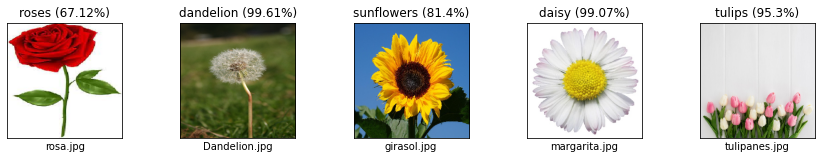

In [81]:
clasificar_todo(custom_resnet_model, imagenes('flores'), flowers, 180, 180)